<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Scatter Plot**


Estimated time needed: **45** minutes


## Overview

In this lab, you will focus on creating and interpreting scatter plots to visualize relationships between variables and trends in the dataset. The provided dataset will be directly loaded into a pandas DataFrame, and various scatter plot-related visualizations will be created to explore developer trends, compensation, and preferences.



## Objectives


In this lab, you will:

- Create and analyze scatter plots to examine relationships between variables.

- Use scatter plots to identify trends and patterns in the dataset.

- Focus on visualizations centered on scatter plots for better data-driven insights.


## Setup: Working with the Database



**Install and import the required libraries**


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

import pandas as pd
import matplotlib.pyplot as plt

#### Step 1: Load the dataset


In [2]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

# (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error
local_file = "survey-data.csv"

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(file_path, local_file)


### Task 1: Exploring Relationships with Scatter Plots



#### 1. Scatter Plot for Age vs. Job Satisfaction



Visualize the relationship between respondents' age (`Age`) and job satisfaction (`JobSatPoints_6`). Use this plot to identify any patterns or trends.




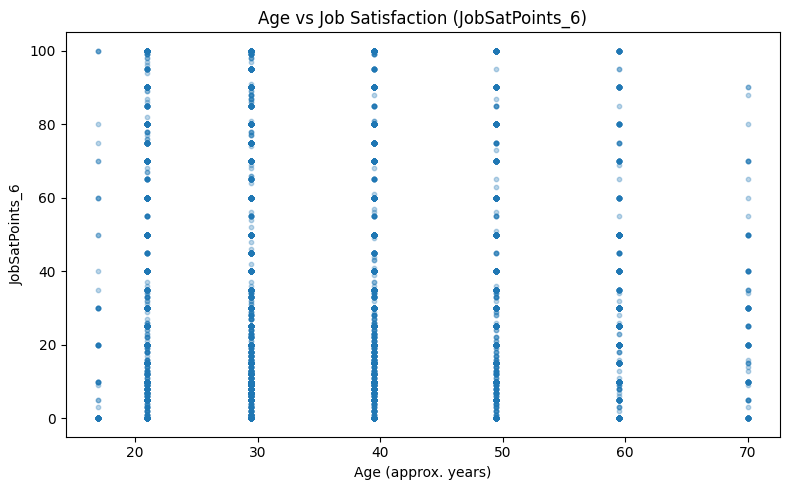

In [3]:
## Write your code here
# Map Age to numeric midpoints
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
plot_df = df[['Age', 'JobSatPoints_6']].copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df = plot_df.dropna(subset=['AgeNum', 'JobSatPoints_6'])

plt.figure(figsize=(8, 5))
plt.scatter(plot_df['AgeNum'], plot_df['JobSatPoints_6'], alpha=0.3, s=10)
plt.title('Age vs Job Satisfaction (JobSatPoints_6)')
plt.xlabel('Age (approx. years)')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

#### 2. Scatter Plot for Compensation vs. Job Satisfaction


Explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) using a scatter plot.


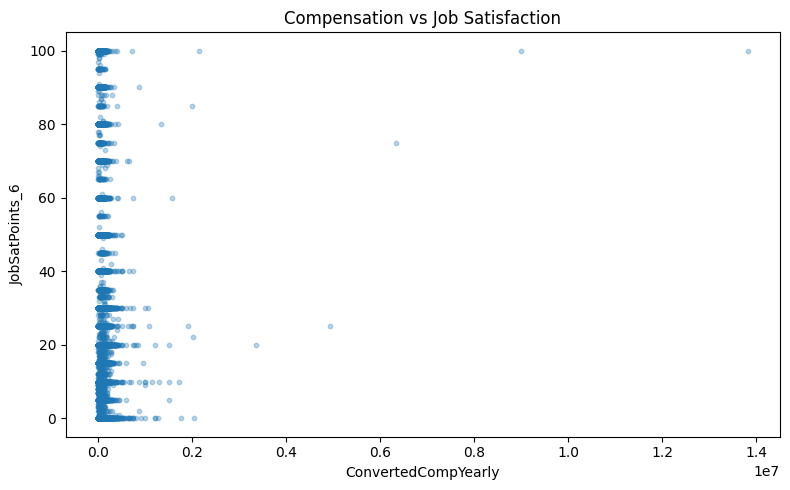

In [4]:
## Write your code here
plot_df = df[['ConvertedCompYearly', 'JobSatPoints_6']].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(plot_df['ConvertedCompYearly'], plot_df['JobSatPoints_6'], alpha=0.3, s=10)
plt.title('Compensation vs Job Satisfaction')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

### Task 2: Enhancing Scatter Plots


#### 1. Scatter Plot with Trend Line for Age vs. Job Satisfaction



Add a regression line to the scatter plot of Age vs. JobSatPoints_6 to highlight trends in the data.


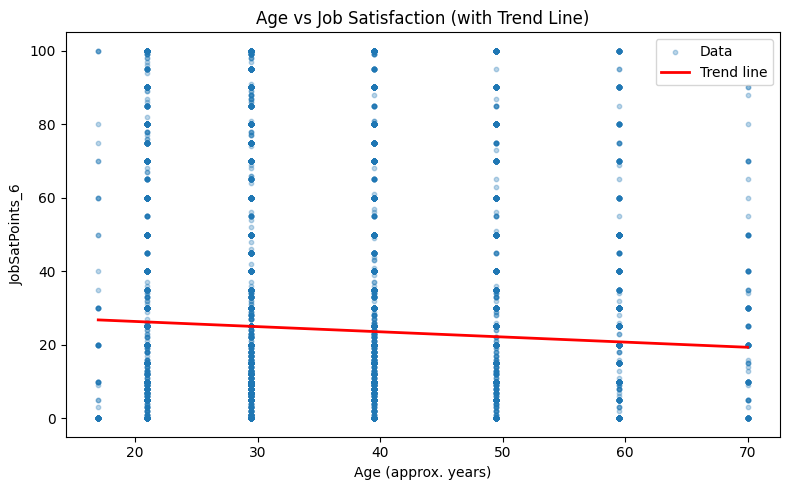

Slope: -0.1405 Intercept: 29.16


In [5]:
## Write your code here
import numpy as np

age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
plot_df = df[['Age', 'JobSatPoints_6']].copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df = plot_df.dropna(subset=['AgeNum', 'JobSatPoints_6'])

x = plot_df['AgeNum']
y = plot_df['JobSatPoints_6']

plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.3, s=10, label='Data')

# Trend line (linear regression via numpy.polyfit)
m, b = np.polyfit(x, y, 1)
x_line = sorted(x.unique())
plt.plot(x_line, [m * xi + b for xi in x_line], color='red', linewidth=2, label='Trend line')

plt.title('Age vs Job Satisfaction (with Trend Line)')
plt.xlabel('Age (approx. years)')
plt.ylabel('JobSatPoints_6')
plt.legend()
plt.tight_layout()
plt.show()

print('Slope:', round(m, 4), 'Intercept:', round(b, 2))

#### 2. Scatter Plot for Age vs. Work Experience


Visualize the relationship between Age (`Age`) and Work Experience (`YearsCodePro`) using a scatter plot.


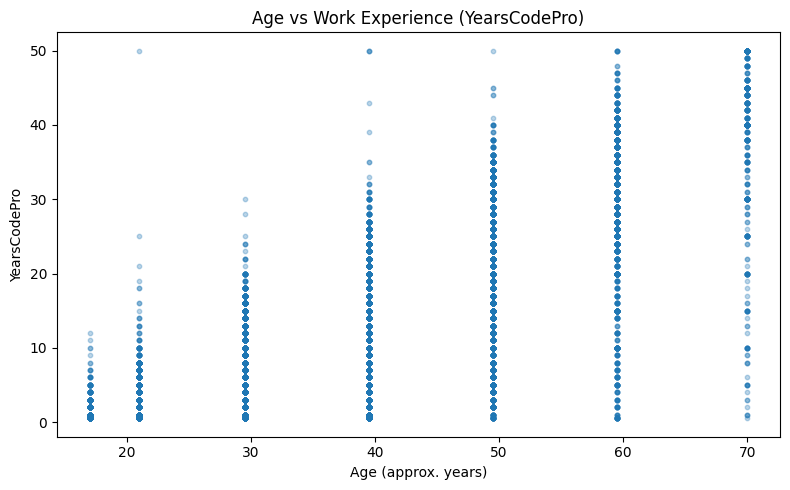

In [6]:
## Write your code here
def to_years(val):
    if pd.isna(val):
        return None
    if isinstance(val, str):
        if val == 'Less than 1 year':
            return 0.5
        if val == 'More than 50 years':
            return 50
        try:
            return float(val)
        except ValueError:
            return None
    return float(val)

age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
plot_df = df[['Age', 'YearsCodePro']].copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df['YearsNum'] = plot_df['YearsCodePro'].apply(to_years)
plot_df = plot_df.dropna(subset=['AgeNum', 'YearsNum'])

plt.figure(figsize=(8, 5))
plt.scatter(plot_df['AgeNum'], plot_df['YearsNum'], alpha=0.3, s=10)
plt.title('Age vs Work Experience (YearsCodePro)')
plt.xlabel('Age (approx. years)')
plt.ylabel('YearsCodePro')
plt.tight_layout()
plt.show()

### Task 3: Combining Scatter Plots with Additional Features


#### 1. Bubble Plot of Compensation vs. Job Satisfaction with Age as Bubble Size



Create a bubble plot to explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), with bubble size representing age.


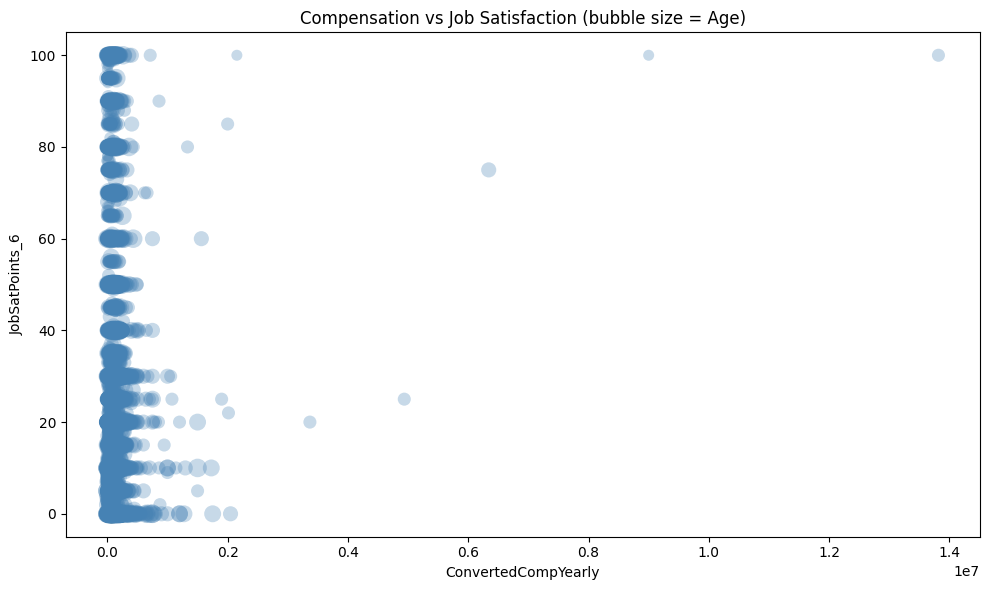

In [7]:
## Write your code here
import numpy as np

age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
bubble_df = df[['ConvertedCompYearly', 'JobSatPoints_6', 'Age']].dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6']).copy()
bubble_df['AgeNum'] = bubble_df['Age'].map(age_mid)
bubble_df = bubble_df.dropna(subset=['AgeNum'])

plt.figure(figsize=(10, 6))
plt.scatter(bubble_df['ConvertedCompYearly'], bubble_df['JobSatPoints_6'],
            s=bubble_df['AgeNum'] * 3, alpha=0.3, c='steelblue', edgecolors='none')
plt.title('Compensation vs Job Satisfaction (bubble size = Age)')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

#### 2. Scatter Plot for Popular Programming Languages by Job Satisfaction


Visualize the popularity of programming languages (`LanguageHaveWorkedWith`) against job satisfaction using a scatter plot. Use points to represent satisfaction levels for each language.


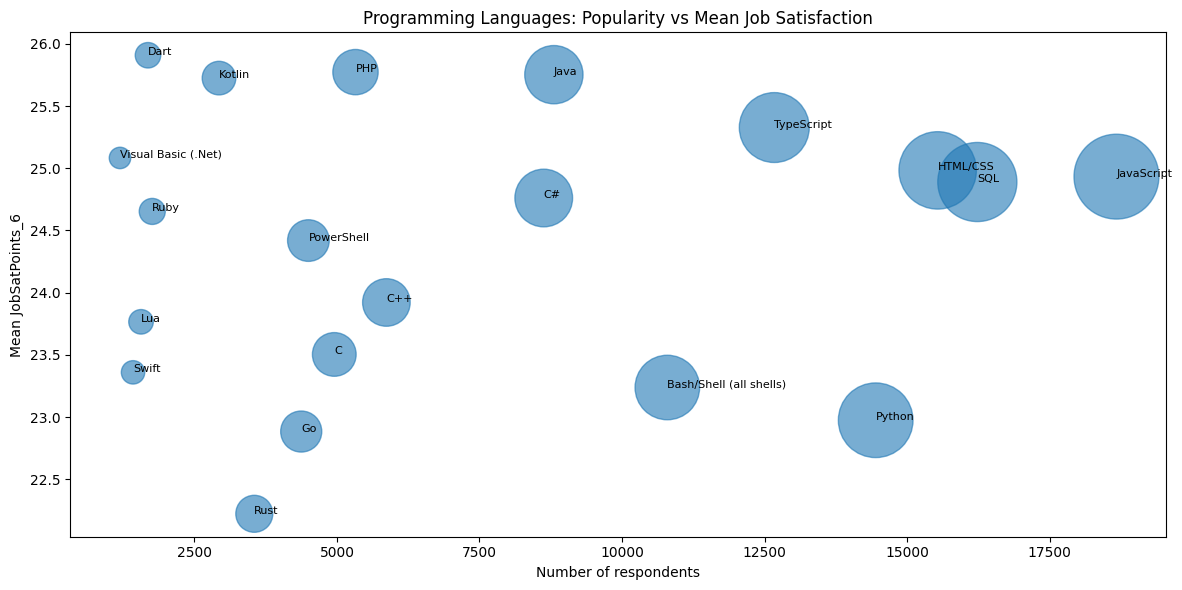

In [8]:
## Write your code here
# Explode LanguageHaveWorkedWith and compute mean JobSatPoints_6 per language
lang_df = df[['LanguageHaveWorkedWith', 'JobSatPoints_6']].dropna(subset=['LanguageHaveWorkedWith', 'JobSatPoints_6']).copy()
lang_df['Language'] = lang_df['LanguageHaveWorkedWith'].str.split(';')
exploded = lang_df.explode('Language')

agg = exploded.groupby('Language').agg(
    mean_jobsat=('JobSatPoints_6', 'mean'),
    respondents=('JobSatPoints_6', 'size'),
).reset_index()
# keep languages with at least 100 respondents
agg = agg[agg['respondents'] >= 100].sort_values('respondents', ascending=False).head(20)

plt.figure(figsize=(12, 6))
plt.scatter(agg['respondents'], agg['mean_jobsat'], s=agg['respondents'] / 5, alpha=0.6)
for _, row in agg.iterrows():
    plt.annotate(row['Language'], (row['respondents'], row['mean_jobsat']), fontsize=8)
plt.title('Programming Languages: Popularity vs Mean Job Satisfaction')
plt.xlabel('Number of respondents')
plt.ylabel('Mean JobSatPoints_6')
plt.tight_layout()
plt.show()

### Task 4: Scatter Plot Comparisons Across Groups


#### 1. Scatter Plot for Compensation vs. Job Satisfaction by Employment Type


Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), categorized by employment type (`Employment`). Use color coding or markers to differentiate between employment types.


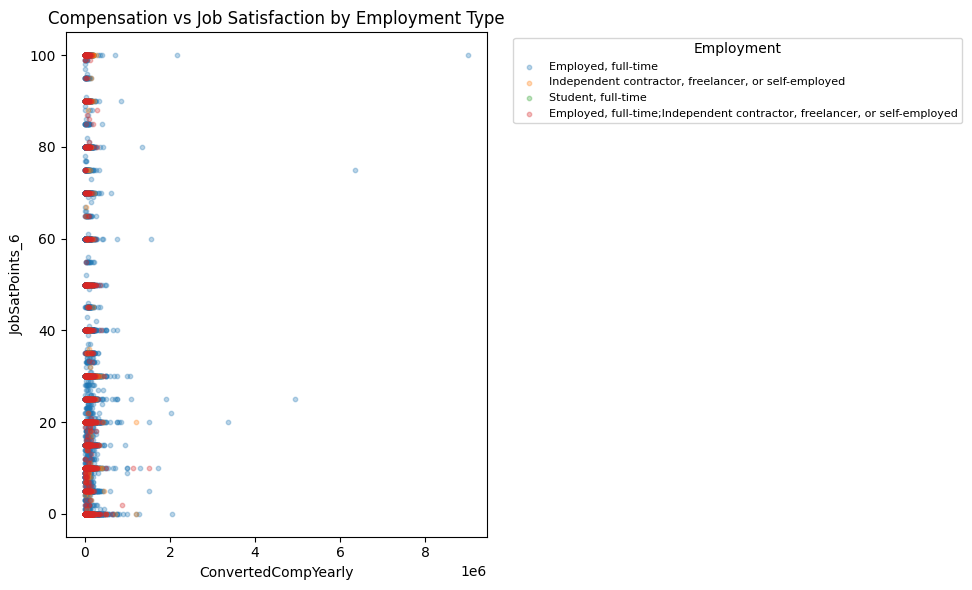

In [9]:
## Write your code here
import numpy as np

# Top employment types for readability
top_emp = df['Employment'].value_counts().head(4).index.tolist()
plot_df = df[df['Employment'].isin(top_emp)][['ConvertedCompYearly', 'JobSatPoints_6', 'Employment']].dropna()

plt.figure(figsize=(10, 6))
for emp in top_emp:
    sub = plot_df[plot_df['Employment'] == emp]
    plt.scatter(sub['ConvertedCompYearly'], sub['JobSatPoints_6'], alpha=0.3, s=10, label=emp)
plt.title('Compensation vs Job Satisfaction by Employment Type')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSatPoints_6')
plt.legend(title='Employment', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

#### 2. Scatter Plot for Work Experience vs. Age Group by Country


Compare work experience (`YearsCodePro`) across different age groups (`Age`) and countries (`Country`). Use colors to represent different countries and markers for age groups.


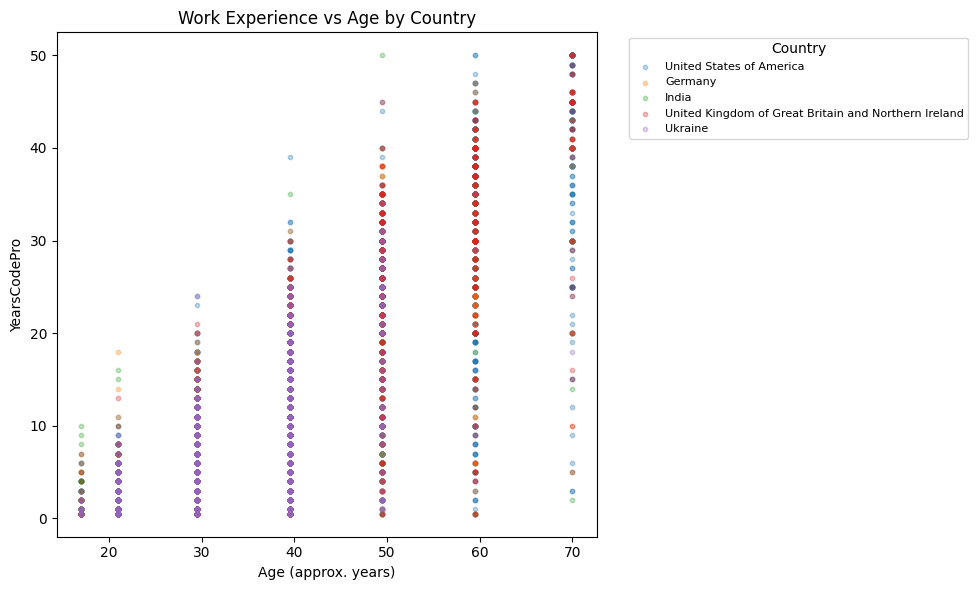

In [10]:
## Write your code here
def to_years(val):
    if pd.isna(val):
        return None
    if isinstance(val, str):
        if val == 'Less than 1 year':
            return 0.5
        if val == 'More than 50 years':
            return 50
        try:
            return float(val)
        except ValueError:
            return None
    return float(val)

age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
top_countries = df['Country'].value_counts().head(5).index.tolist()
plot_df = df[df['Country'].isin(top_countries)][['YearsCodePro', 'Age', 'Country']].copy()
plot_df['YearsNum'] = plot_df['YearsCodePro'].apply(to_years)
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df = plot_df.dropna(subset=['YearsNum', 'AgeNum'])

plt.figure(figsize=(10, 6))
for country in top_countries:
    sub = plot_df[plot_df['Country'] == country]
    plt.scatter(sub['AgeNum'], sub['YearsNum'], alpha=0.3, s=10, label=country)
plt.title('Work Experience vs Age by Country')
plt.xlabel('Age (approx. years)')
plt.ylabel('YearsCodePro')
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### Final Step: Review


With these scatter plots, you will have analyzed data relationships across multiple dimensions, including compensation, job satisfaction, employment types, and demographics, to uncover meaningful trends in the developer community.


### Summary


After completing this lab, you will be able to:
- Analyze how numerical variables relate across specific groups, such as employment types and countries.
- Use scatter plots effectively to represent multiple variables with color, size, and markers.
- Gain insights into compensation, satisfaction, and demographic trends using advanced scatter plot techniques.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
